In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/all_data/all_machines_combined.csv"
)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (1930, 17)


,Machine_ID,Machine_Type,Failure_Mode,Cycle,Temperature_C,Vibration_mm_s,Pressure_bar,Rotational_Speed_RPM,Load_Fraction,Torque_Nm,Current_A,Acoustic_dB,Wear_Level,Health_Index,Anomaly_Score,Failure,RUL_Cycles
0,CNC_001,CNC_Mill,Bearing,1,68.987,0.2351,2.117,1518.64,0.6513,46.734,9.213,56.022,0.0000,100.000,0.1342,0,259
1,CNC_001,CNC_Mill,Bearing,2,69.431,0.1894,2.126,1517.67,0.5961,46.603,9.480,55.789,0.0000,99.961,0.2990,0,258
2,CNC_001,CNC_Mill,Bearing,3,68.779,0.2385,2.119,1520.83,0.6336,46.313,9.612,54.954,0.0022,99.760,0.2269,0,257
3,CNC_001,CNC_Mill,Bearing,4,68.926,0.2047,2.110,1531.69,0.6898,48.403,9.907,54.567,0.0000,99.884,0.0469,0,256
4,CNC_001,CNC_Mill,Bearing,5,68.704,0.2086,2.079,1516.70,0.5900,48.188,9.080,54.424,0.0006,99.802,0.2841,0,255


In [2]:
print("RUL statistics:")

display(
    df["RUL_Cycles"].describe()
)

RUL statistics:


count    1930.000000
mean      139.538860
std        83.301714
min         0.000000
25%        68.250000
50%       137.000000
75%       206.000000
max       329.000000
Name: RUL_Cycles, dtype: float64

In [3]:
print("Missing RUL values:")
print(df["RUL_Cycles"].isna().sum())

print("\nMinimum RUL:")
print(df["RUL_Cycles"].min())

print("\nMaximum RUL:")
print(df["RUL_Cycles"].max())

Missing RUL values:
0

Minimum RUL:
0

Maximum RUL:
329


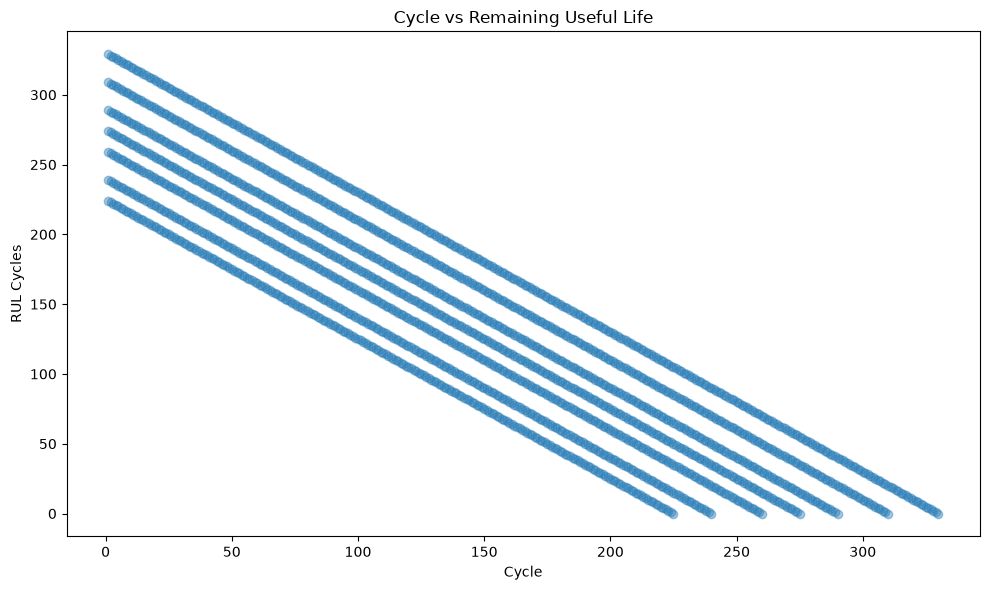

In [4]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Cycle"],
    df["RUL_Cycles"],
    alpha=0.4
)

plt.xlabel("Cycle")
plt.ylabel("RUL Cycles")
plt.title("Cycle vs Remaining Useful Life")

plt.tight_layout()
plt.show()

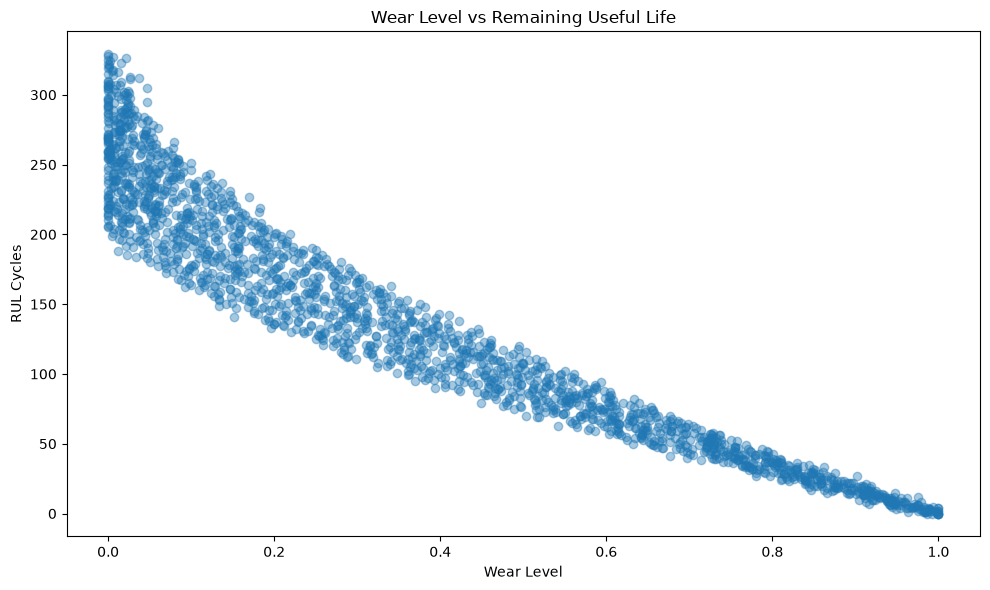

In [5]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Wear_Level"],
    df["RUL_Cycles"],
    alpha=0.4
)

plt.xlabel("Wear Level")
plt.ylabel("RUL Cycles")
plt.title("Wear Level vs Remaining Useful Life")

plt.tight_layout()
plt.show()

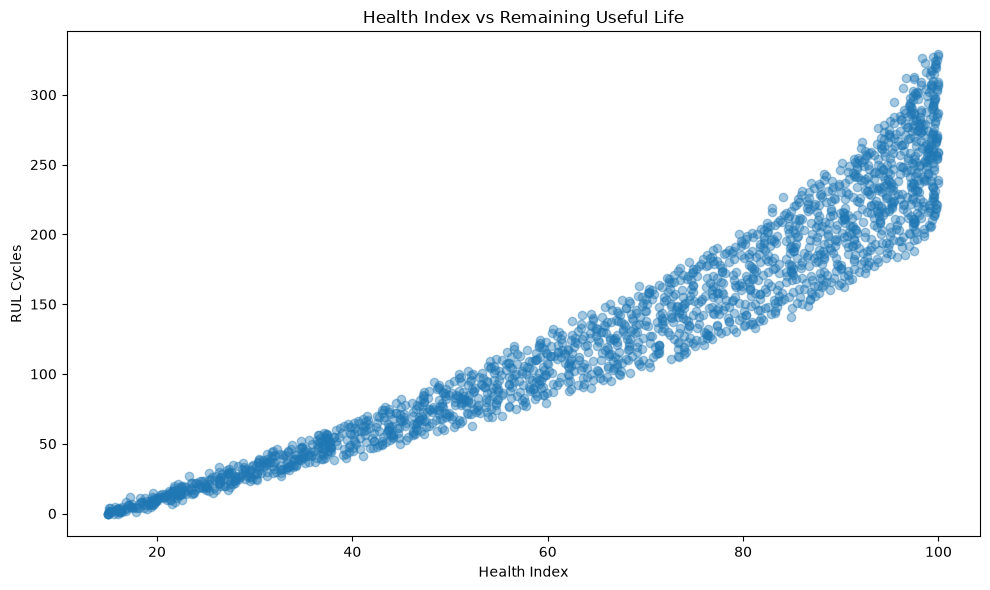

In [6]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Health_Index"],
    df["RUL_Cycles"],
    alpha=0.4
)

plt.xlabel("Health Index")
plt.ylabel("RUL Cycles")
plt.title("Health Index vs Remaining Useful Life")

plt.tight_layout()
plt.show()

In [7]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

rul_correlations = (
    df[numeric_columns]
    .corr()["RUL_Cycles"]
    .sort_values(ascending=False)
)

display(rul_correlations)

RUL_Cycles              1.000000
Health_Index            0.956089
Rotational_Speed_RPM    0.298672
Failure                -0.409372
Pressure_bar           -0.645066
Torque_Nm              -0.711311
Load_Fraction          -0.723111
Current_A              -0.797632
Temperature_C          -0.818925
Vibration_mm_s         -0.902392
Cycle                  -0.913770
Acoustic_dB            -0.919039
Anomaly_Score          -0.941392
Wear_Level             -0.952086
Name: RUL_Cycles, dtype: float64

In [8]:
# ============================================
# RUL MODEL
# STEP 7: FEATURE SELECTION
# ============================================

rul_features = [
    "Cycle",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Rotational_Speed_RPM",
    "Load_Fraction",
    "Torque_Nm",
    "Current_A",
    "Acoustic_dB",
    "Wear_Level",
    "Health_Index",
    "Anomaly_Score",
    "Machine_Type"
]

rul_target = "RUL_Cycles"

X_rul = df[rul_features].copy()
y_rul = df[rul_target].copy()

print("RUL Features:")
for feature in rul_features:
    print("-", feature)

print("\nX shape:", X_rul.shape)
print("y shape:", y_rul.shape)

display(X_rul.head())

RUL Features:
- Cycle
- Temperature_C
- Vibration_mm_s
- Pressure_bar
- Rotational_Speed_RPM
- Load_Fraction
- Torque_Nm
- Current_A
- Acoustic_dB
- Wear_Level
- Health_Index
- Anomaly_Score
- Machine_Type

X shape: (1930, 13)
y shape: (1930,)


,Cycle,Temperature_C,Vibration_mm_s,Pressure_bar,Rotational_Speed_RPM,Load_Fraction,Torque_Nm,Current_A,Acoustic_dB,Wear_Level,Health_Index,Anomaly_Score,Machine_Type
0,1,68.987,0.2351,2.117,1518.64,0.6513,46.734,9.213,56.022,0.0000,100.000,0.1342,CNC_Mill
1,2,69.431,0.1894,2.126,1517.67,0.5961,46.603,9.480,55.789,0.0000,99.961,0.2990,CNC_Mill
2,3,68.779,0.2385,2.119,1520.83,0.6336,46.313,9.612,54.954,0.0022,99.760,0.2269,CNC_Mill
3,4,68.926,0.2047,2.110,1531.69,0.6898,48.403,9.907,54.567,0.0000,99.884,0.0469,CNC_Mill
4,5,68.704,0.2086,2.079,1516.70,0.5900,48.188,9.080,54.424,0.0006,99.802,0.2841,CNC_Mill


In [9]:
# ============================================
# STEP 8: TRAIN / VALIDATION / TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

X_train_rul, X_temp_rul, y_train_rul, y_temp_rul = train_test_split(
    X_rul,
    y_rul,
    test_size=0.30,
    random_state=42
)

X_val_rul, X_test_rul, y_val_rul, y_test_rul = train_test_split(
    X_temp_rul,
    y_temp_rul,
    test_size=0.50,
    random_state=42
)

print("Train shape:", X_train_rul.shape)
print("Validation shape:", X_val_rul.shape)
print("Test shape:", X_test_rul.shape)

print("\nRUL distribution:")

print("\nTraining:")
print(y_train_rul.describe())

print("\nValidation:")
print(y_val_rul.describe())

print("\nTesting:")
print(y_test_rul.describe())

Train shape: (1351, 13)
Validation shape: (289, 13)
Test shape: (290, 13)

RUL distribution:

Training:
count    1351.000000
mean      139.430052
std        82.985617
min         0.000000
25%        69.000000
50%       136.000000
75%       206.000000
max       329.000000
Name: RUL_Cycles, dtype: float64

Validation:
count    289.000000
mean     138.321799
std       85.071724
min        0.000000
25%       65.000000
50%      136.000000
75%      208.000000
max      318.000000
Name: RUL_Cycles, dtype: float64

Testing:
count    290.000000
mean     141.258621
std       83.254053
min        0.000000
25%       68.750000
50%      142.500000
75%      207.750000
max      324.000000
Name: RUL_Cycles, dtype: float64


In [11]:
# ============================================
# STEP 9: PREPROCESSING
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

categorical_features_rul = X_rul.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

numerical_features_rul = X_rul.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features_rul)

print("\nNumerical Features:")
print(numerical_features_rul)

Categorical Features:
['Machine_Type']

Numerical Features:
['Cycle', 'Temperature_C', 'Vibration_mm_s', 'Pressure_bar', 'Rotational_Speed_RPM', 'Load_Fraction', 'Torque_Nm', 'Current_A', 'Acoustic_dB', 'Wear_Level', 'Health_Index', 'Anomaly_Score']


In [13]:
# ============================================
# STEP 10: BASELINE REGRESSION MODEL
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor

baseline_rul = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_rul
        ),
        (
            "model",
            DummyRegressor(
                strategy="mean"
            )
        )
    ]
)

baseline_rul.fit(
    X_train_rul,
    y_train_rul
)

baseline_rul_predictions = baseline_rul.predict(
    X_val_rul
)

print("Baseline RUL model trained successfully.")

Baseline RUL model trained successfully.


In [14]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

baseline_mae = mean_absolute_error(
    y_val_rul,
    baseline_rul_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_val_rul,
        baseline_rul_predictions
    )
)

baseline_r2 = r2_score(
    y_val_rul,
    baseline_rul_predictions
)

print("Baseline RUL Results")
print("--------------------")
print("MAE :", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R²  :", round(baseline_r2, 4))

Baseline RUL Results
--------------------
MAE : 72.6115
RMSE: 84.9316
R²  : -0.0002


In [15]:
# ============================================
# STEP 11: RANDOM FOREST REGRESSOR
# ============================================

from sklearn.ensemble import RandomForestRegressor

rf_rul = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_rul
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_rul.fit(
    X_train_rul,
    y_train_rul
)

print("Random Forest RUL regressor trained successfully.")

Random Forest RUL regressor trained successfully.


In [16]:
# ============================================
# RANDOM FOREST RUL EVALUATION
# ============================================

rf_rul_predictions = rf_rul.predict(
    X_val_rul
)

rf_rul_mae = mean_absolute_error(
    y_val_rul,
    rf_rul_predictions
)

rf_rul_rmse = np.sqrt(
    mean_squared_error(
        y_val_rul,
        rf_rul_predictions
    )
)

rf_rul_r2 = r2_score(
    y_val_rul,
    rf_rul_predictions
)

print("Random Forest RUL Results")
print("-------------------------")
print("MAE :", round(rf_rul_mae, 4))
print("RMSE:", round(rf_rul_rmse, 4))
print("R²  :", round(rf_rul_r2, 4))

Random Forest RUL Results
-------------------------
MAE : 4.2588
RMSE: 5.8941
R²  : 0.9952


In [17]:
# ============================================
# STEP 12: XGBOOST REGRESSOR
# ============================================

from xgboost import XGBRegressor

xgb_rul = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_rul
        ),
        (
            "model",
            XGBRegressor(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=6,
                random_state=42,
                objective="reg:squarederror"
            )
        )
    ]
)

xgb_rul.fit(
    X_train_rul,
    y_train_rul
)

print("XGBoost RUL regressor trained successfully.")

XGBoost RUL regressor trained successfully.


In [18]:
# ============================================
# XGBOOST RUL EVALUATION
# ============================================

xgb_rul_predictions = xgb_rul.predict(
    X_val_rul
)

xgb_rul_mae = mean_absolute_error(
    y_val_rul,
    xgb_rul_predictions
)

xgb_rul_rmse = np.sqrt(
    mean_squared_error(
        y_val_rul,
        xgb_rul_predictions
    )
)

xgb_rul_r2 = r2_score(
    y_val_rul,
    xgb_rul_predictions
)

print("XGBoost RUL Results")
print("-------------------")
print("MAE :", round(xgb_rul_mae, 4))
print("RMSE:", round(xgb_rul_rmse, 4))
print("R²  :", round(xgb_rul_r2, 4))

XGBoost RUL Results
-------------------
MAE : 3.4499
RMSE: 4.805
R²  : 0.9968


In [19]:
# ============================================
# STEP 13: LIGHTGBM REGRESSOR
# ============================================

from lightgbm import LGBMRegressor

lgb_rul = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_rul
        ),
        (
            "model",
            LGBMRegressor(
                n_estimators=300,
                learning_rate=0.05,
                random_state=42,
                verbosity=-1
            )
        )
    ]
)

lgb_rul.fit(
    X_train_rul,
    y_train_rul
)

print("LightGBM RUL regressor trained successfully.")

LightGBM RUL regressor trained successfully.


In [20]:
# ============================================
# LIGHTGBM RUL EVALUATION
# ============================================

lgb_rul_predictions = lgb_rul.predict(
    X_val_rul
)

lgb_rul_mae = mean_absolute_error(
    y_val_rul,
    lgb_rul_predictions
)

lgb_rul_rmse = np.sqrt(
    mean_squared_error(
        y_val_rul,
        lgb_rul_predictions
    )
)

lgb_rul_r2 = r2_score(
    y_val_rul,
    lgb_rul_predictions
)

print("LightGBM RUL Results")
print("--------------------")
print("MAE :", round(lgb_rul_mae, 4))
print("RMSE:", round(lgb_rul_rmse, 4))
print("R²  :", round(lgb_rul_r2, 4))

LightGBM RUL Results
--------------------
MAE : 3.3383
RMSE: 4.4636
R²  : 0.9972


In [21]:
# ============================================
# STEP 14: RUL MODEL COMPARISON
# ============================================

rul_results = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": baseline_r2
    },
    {
        "Model": "Random Forest",
        "MAE": rf_rul_mae,
        "RMSE": rf_rul_rmse,
        "R2": rf_rul_r2
    },
    {
        "Model": "XGBoost",
        "MAE": xgb_rul_mae,
        "RMSE": xgb_rul_rmse,
        "R2": xgb_rul_r2
    },
    {
        "Model": "LightGBM",
        "MAE": lgb_rul_mae,
        "RMSE": lgb_rul_rmse,
        "R2": lgb_rul_r2
    }
])

display(
    rul_results.round(4)
)

,Model,MAE,RMSE,R2
0,Dummy Regressor,72.6115,84.9316,-0.0002
1,Random Forest,4.2588,5.8941,0.9952
2,XGBoost,3.4499,4.8050,0.9968
3,LightGBM,3.3383,4.4636,0.9972


In [22]:
rul_results_sorted = rul_results.sort_values(
    by=["MAE", "RMSE", "R2"],
    ascending=[True, True, False]
)

display(
    rul_results_sorted.round(4)
)

best_rul_model_name = rul_results_sorted.iloc[0]["Model"]

print("Best RUL model based on validation metrics:")
print(best_rul_model_name)

,Model,MAE,RMSE,R2
3,LightGBM,3.3383,4.4636,0.9972
2,XGBoost,3.4499,4.8050,0.9968
1,Random Forest,4.2588,5.8941,0.9952
0,Dummy Regressor,72.6115,84.9316,-0.0002


Best RUL model based on validation metrics:
LightGBM


In [23]:
rul_results_sorted = rul_results.sort_values(
    by=["MAE", "RMSE", "R2"],
    ascending=[True, True, False]
)

display(
    rul_results_sorted.round(4)
)

best_rul_model_name = rul_results_sorted.iloc[0]["Model"]

print("Best RUL model based on validation metrics:")
print(best_rul_model_name)

,Model,MAE,RMSE,R2
3,LightGBM,3.3383,4.4636,0.9972
2,XGBoost,3.4499,4.8050,0.9968
1,Random Forest,4.2588,5.8941,0.9952
0,Dummy Regressor,72.6115,84.9316,-0.0002


Best RUL model based on validation metrics:
LightGBM


In [24]:
# ============================================
# STEP 15: SELECT BEST RUL MODEL
# ============================================

if best_rul_model_name == "Random Forest":
    final_rul_model = rf_rul

elif best_rul_model_name == "XGBoost":
    final_rul_model = xgb_rul

elif best_rul_model_name == "LightGBM":
    final_rul_model = lgb_rul

else:
    raise ValueError("Unknown RUL model selected.")

print(
    "Selected final RUL model:",
    best_rul_model_name
)

Selected final RUL model: LightGBM


In [25]:
# ============================================
# STEP 16: FINAL RUL TEST EVALUATION
# ============================================

final_rul_predictions = final_rul_model.predict(
    X_test_rul
)

final_rul_mae = mean_absolute_error(
    y_test_rul,
    final_rul_predictions
)

final_rul_rmse = np.sqrt(
    mean_squared_error(
        y_test_rul,
        final_rul_predictions
    )
)

final_rul_r2 = r2_score(
    y_test_rul,
    final_rul_predictions
)

final_rul_test_metrics = {
    "Model": best_rul_model_name,
    "MAE": final_rul_mae,
    "RMSE": final_rul_rmse,
    "R2": final_rul_r2
}

final_rul_test_results = pd.DataFrame(
    [final_rul_test_metrics]
)

display(
    final_rul_test_results.round(4)
)

,Model,MAE,RMSE,R2
0,LightGBM,3.5989,4.7229,0.9968


In [26]:
# ============================================
# STEP 17: ACTUAL VS PREDICTED RUL
# ============================================

rul_prediction_results = pd.DataFrame({
    "Actual_RUL": y_test_rul.values,
    "Predicted_RUL": final_rul_predictions
})

rul_prediction_results["Absolute_Error"] = (
    abs(
        rul_prediction_results["Actual_RUL"]
        - rul_prediction_results["Predicted_RUL"]
    )
)

display(
    rul_prediction_results.head(20).round(2)
)

,Actual_RUL,Predicted_RUL,Absolute_Error
0,119,113.32,5.68
1,182,180.48,1.52
2,120,110.35,9.65
3,223,234.18,11.18
4,143,140.43,2.57
5,198,189.51,8.49
6,74,67.92,6.08
7,87,83.56,3.44
8,3,6.32,3.32
9,78,81.21,3.21


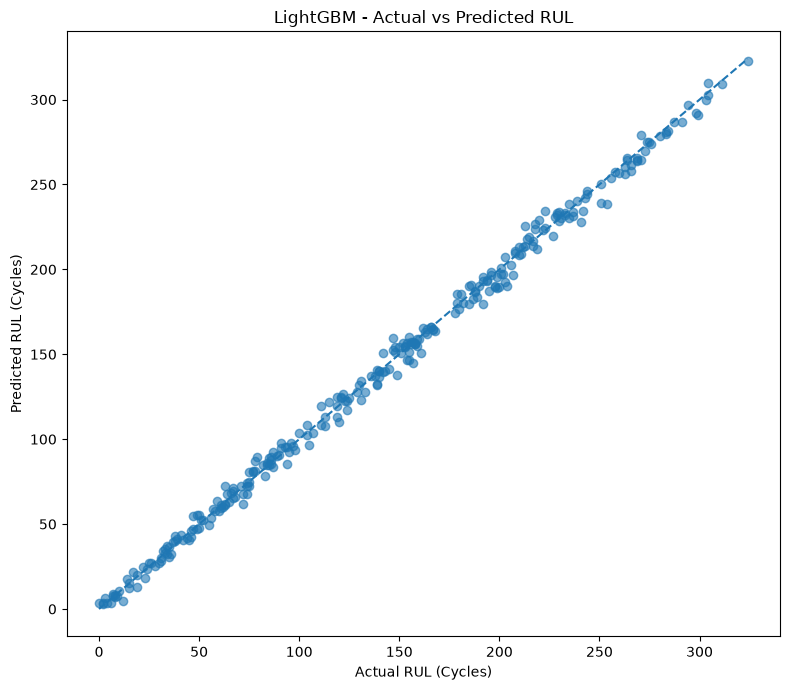

In [27]:
# ============================================
# STEP 18: ACTUAL VS PREDICTED VISUALIZATION
# ============================================

plt.figure(figsize=(8, 7))

plt.scatter(
    y_test_rul,
    final_rul_predictions,
    alpha=0.6
)

min_rul = min(
    y_test_rul.min(),
    final_rul_predictions.min()
)

max_rul = max(
    y_test_rul.max(),
    final_rul_predictions.max()
)

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL (Cycles)")
plt.ylabel("Predicted RUL (Cycles)")
plt.title(
    "LightGBM - Actual vs Predicted RUL"
)

plt.tight_layout()
plt.show()

In [28]:
print("Final RUL Test Results")
print("---------------------")
print("Model:", best_rul_model_name)
print("MAE :", round(final_rul_mae, 4))
print("RMSE:", round(final_rul_rmse, 4))
print("R²  :", round(final_rul_r2, 4))

Final RUL Test Results
---------------------
Model: LightGBM
MAE : 3.5989
RMSE: 4.7229
R²  : 0.9968


In [29]:
# ============================================
# STEP 19: RUL ERROR ANALYSIS
# ============================================

rul_prediction_results = rul_prediction_results.sort_values(
    "Absolute_Error",
    ascending=False
)

display(
    rul_prediction_results.head(20).round(2)
)

,Actual_RUL,Predicted_RUL,Absolute_Error
110,254,238.24,15.76
90,204,190.39,13.61
245,241,227.77,13.23
122,147,159.71,12.71
166,213,225.52,12.52
25,192,179.52,12.48
87,251,238.87,12.13
207,157,144.94,12.06
3,223,234.18,11.18
126,149,137.95,11.05


In [30]:
# ============================================
# STEP 20: SAVE FINAL RUL MODEL
# ============================================

import joblib
import os

os.makedirs(
    "../models",
    exist_ok=True
)

rul_model_path = "../models/rul_prediction_model.pkl"

joblib.dump(
    final_rul_model,
    rul_model_path
)

print("Final RUL model saved successfully!")
print("Model:", best_rul_model_name)
print("Path:", rul_model_path)

Final RUL model saved successfully!
Model: LightGBM
Path: ../models/rul_prediction_model.pkl
